# Task 1: is the OOF threshold right for the 10-model average?

`Task1/train.py` เลือก threshold บน OOF 10 fold (แต่ละแถวได้คะแนนจากโมเดล**ตัวเดียว**, threshold 0.182, OOF F2 0.8388) แต่คอลัมน์ test คือ**ค่าเฉลี่ย**ของ 10 โมเดล ค่าเฉลี่ยสุดโต่งน้อยกว่า threshold ที่ดีที่สุดของมันจึงอาจต่างจากของ OOF เล็กน้อย

เช็คด้วยการจำลองซ้อนบนแถว train ที่มี label เท่านั้น (`experiments/task1/eda/threshold_ensemble.py`):
- แบ่งชั้นนอก StratifiedKFold 3, seed 342 แต่ละ fold ชั้นนอก H กับส่วนที่เหลือ R
- รัน `Task1/train.py` ตัวจริงบน R (`run.main`, 10 fold, seed / profile / CatBoost เหมือนเดิม, 12 threads) โดยให้ feature ของ H (ไม่มี label) เป็น test
- pipeline fit imputer บนส่วน train เท่านั้น H จึงไม่มีผลกับ feature ของ R
- เก็บ OOF ชั้นใน (คะแนนโมเดลเดี่ยว) ของ R และค่าเฉลี่ย 10 โมเดลบน H

ไม่อ่าน test.csv หรือคำทำนายบน test และไม่ตั้ง threshold จากสัดส่วนที่ทายบน test

**กฎตัดสิน:** เปลี่ยน threshold เฉพาะถ้า honest gain ≥ +0.0015 F2 (คนโกง) และชนะครบ 3 fold ชั้นนอก ถ้า oracle gap เองยัง < +0.0015 ให้หยุดและสรุปว่า threshold ถูกแล้ว

## Imports

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.width', 200)  # keep wide tables on one line instead of "..."

## Setup

In [2]:
# Find the repo root (the folder with `run.py`), move there and add it to `sys.path`, so paths like `outputs/...` and `import pis` work wherever the kernel started.
ROOT = Path.cwd().resolve()
while not (ROOT / 'run.py').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('run.py not found; open this notebook inside the repo')
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'experiments' / 'task1' / 'eda'))

from pis.tabular import _threshold
import threshold_ensemble as te   # experiments/task1/eda/threshold_ensemble.py (run it first; this notebook only reads its outputs)

BLUE, RED, ORANGE, INK, GRID = '#2a78d6', '#e34948', '#eb6834', '#52514e', '#e5e4df'
MIN_GAIN = 0.0015


def tidy(ax, grid='y'):
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)


print(f"repo root: {ROOT}")

repo root: C:\Users\acer\Desktop\cpe342\project\player-intelligence-system-cpe342


## Load the nested runs

แต่ละ fold ชั้นนอก: R กับ H ต้องไม่ซ้ำกัน และรวมกันต้องเป็นแถวที่มี label ทั้งหมด (90,816)

In [3]:
scores = te.load_scores()
all_ids = np.concatenate([s['h_ids'] for s in scores])
assert len(all_ids) == len(set(all_ids)) == 90816
for s in scores:
    assert not set(s['r_ids']) & set(s['h_ids'])
pd.DataFrame([{'outer fold': k, 'R rows': len(s['r_ids']), 'H rows': len(s['h_ids']), 'cheaters in H': s['h_y'].mean()}
              for k, s in enumerate(scores, 1)]).set_index('outer fold').style.format({'R rows': '{:,}', 'H rows': '{:,}', 'cheaters in H': '{:.1%}'})

,R rows,H rows,cheaters in H
outer fold,,,
1,"60,544","30,272",34.9%
2,"60,544","30,272",34.9%
3,"60,544","30,272",34.9%


## 1. Per outer fold: OOF threshold vs the best threshold for the ensemble

- `t_oof` = `_threshold` บน OOF ชั้นในของ R (สิ่งที่ pipeline ทำตอนนี้)
- `F2 on H at t_oof` = F2 (คนโกง) ของค่าเฉลี่ย 10 โมเดลบน H ที่ threshold นั้น
- `t_best_H` = threshold ที่ดีที่สุดสำหรับค่าเฉลี่ยบน H (in-sample, oracle)
- `gap` = F2 ที่ `t_best_H` − F2 ที่ `t_oof` (ขอบบนของสิ่งที่การแก้ threshold จะได้)

In [4]:
table = te.per_fold_table(scores)
pooled_oof = te.pooled(scores, table['t_oof'])
pooled_best = te.pooled(scores, table['t_best_H'])
print(f"pooled over H: F2 at t_oof {pooled_oof:.4f} | at t_best_H (oracle) {pooled_best:.4f} | gap {pooled_best - pooled_oof:+.4f}")
table.style.format({'t_oof': '{:.4f}', 'OOF F2 on R': '{:.4f}', 't_best_H': '{:.4f}', 'shift': '{:+.4f}', 'logit shift': '{:+.3f}',
                    'F2 on H at t_oof': '{:.4f}', 'F2 on H at t_best_H': '{:.4f}', 'gap (oracle)': '{:+.4f}'}) \
    .set_caption('Threshold chosen on the single-model OOF vs the best threshold for the 10-model average')

pooled over H: F2 at t_oof 0.8381 | at t_best_H (oracle) 0.8386 | gap +0.0005


,t_oof,OOF F2 on R,t_best_H,shift,logit shift,F2 on H at t_oof,F2 on H at t_best_H,gap (oracle)
outer fold,,,,,,,,
1,0.1696,0.8380,0.1814,+0.0117,+0.081,0.8387,0.8397,+0.0010
2,0.1825,0.8398,0.1883,+0.0058,+0.039,0.8370,0.8370,+0.0001
3,0.1765,0.8376,0.1876,+0.0111,+0.075,0.8386,0.8390,+0.0005


## 2. Score distributions and the F2 curve around 0.18

ค่าเฉลี่ย 10 โมเดลควรกระจายแคบกว่าคะแนนของโมเดลเดี่ยว ดูว่าต่างกันแค่ไหน และ F2 รอบ threshold ราบแค่ไหน

In [5]:
rows = []
for k, s in enumerate(scores, 1):
    for name, p in (('R: single-model OOF', s['r_oof']), ('H: 10-model average', s['h_ens'])):
        z = te.logit(p)
        t_oof = table.loc[k, 't_oof']
        rows.append({'outer fold': k, 'scores': name, 'mean': p.mean(), 'std of logit': z.std(),
                     '5%': np.quantile(p, 0.05), '25%': np.quantile(p, 0.25), 'median': np.median(p), '75%': np.quantile(p, 0.75),
                     '95%': np.quantile(p, 0.95), 'share >= t_oof': (p >= t_oof).mean()})
dist = pd.DataFrame(rows).set_index(['outer fold', 'scores'])
dist.style.format('{:.4f}').format('{:.1%}', subset=['share >= t_oof']).set_caption('Single-model OOF on R vs 10-model average on H')

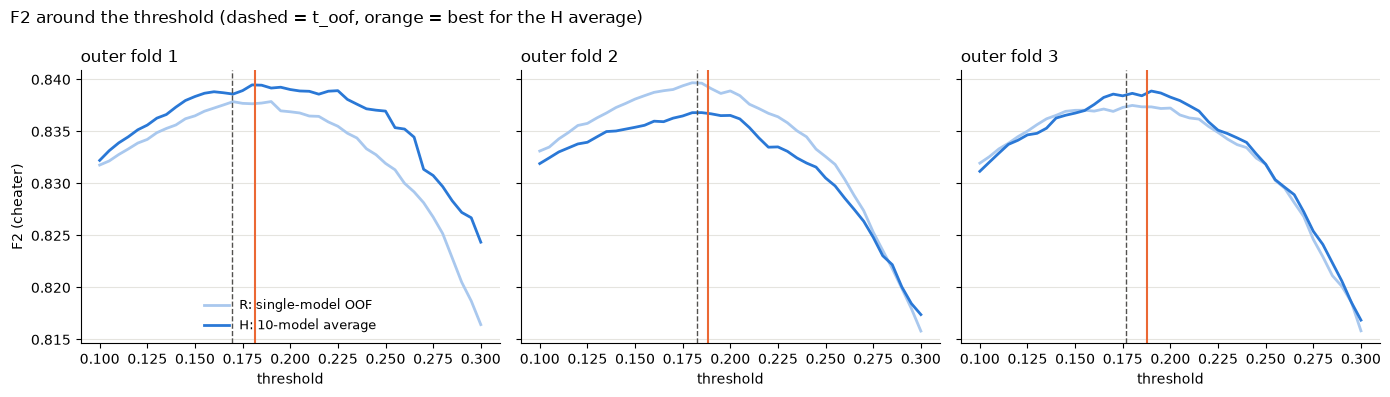

In [6]:
grid = np.round(np.arange(0.10, 0.301, 0.005), 3)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (k, s) in zip(axes, enumerate(scores, 1)):
    ax.plot(grid, [te.f2(s['r_y'], s['r_oof'], t) for t in grid], color='#a9c8ee', linewidth=2, label='R: single-model OOF')
    ax.plot(grid, [te.f2(s['h_y'], s['h_ens'], t) for t in grid], color=BLUE, linewidth=2, label='H: 10-model average')
    ax.axvline(table.loc[k, 't_oof'], color=INK, linestyle='--', linewidth=1)
    ax.axvline(table.loc[k, 't_best_H'], color=ORANGE, linewidth=1.5)
    ax.set_title(f'outer fold {k}', loc='left')
    ax.set_xlabel('threshold')
    tidy(ax)
axes[0].set_ylabel('F2 (cheater)')
axes[0].legend(frameon=False, fontsize=9, loc='lower center')
fig.suptitle('F2 around the threshold (dashed = t_oof, orange = best for the H average)', x=0.01, ha='left')
plt.tight_layout()
plt.show()

**NOTE:**


Averaging 10 fold models narrows the scores much less than expected. The std of the logit is 4.26 vs 4.26, 4.39 vs 4.34 and 4.39 vs 4.32. The share of rows above `t_oof` is the same within 0.6 points (65.0% vs 64.9%, 63.2% vs 63.5%, 64.6% vs 64.0%), and the quantiles agree to the third decimal. Each fold model trains on 90% of the same rows, so the 10 models nearly agree and their average looks like a single model.

The F2 curve is flat around 0.18. On H, every threshold from about 0.16 to 0.20 lands within a few thousandths of the best, and `t_oof` (dashed line) is always inside that plateau.

## 3. Train-only correction, honest

ประมาณการเลื่อน threshold จาก 2 fold ชั้นนอก (`t_best_H` − `t_oof` เฉลี่ย, แบบบวกในความน่าจะเป็น และแบบบวกใน logit) แล้วใช้กับ `t_oof` ของ fold ที่ 3 วัด F2 บน H ของ fold นั้น

ทางเลือก "OOF ที่เหมือน ensemble" (เลือก threshold บน R จากคะแนนที่เป็นค่าเฉลี่ยของหลายโมเดลที่ไม่เคยเห็นแถวนั้น) ทำไม่ได้ใน pipeline นี้ ใน 10-fold แต่ละแถวมีโมเดลที่ไม่เห็นมันแค่ตัวเดียว (ตัวของ fold ที่แถวนั้นอยู่) จะได้คะแนนเฉลี่ยแบบนั้นต้องเทรนซ้ำหลายรอบด้วยการแบ่งต่างกัน ซึ่งไม่ใช่สิ่งที่ pipeline ผลิตได้ราคาถูก จึงข้าม

In [7]:
honest = te.honest_correction(scores, table)
summary = pd.Series({'t_oof (current)': te.pooled(scores, honest['t_oof']), 'additive shift': te.pooled(scores, honest['t additive']),
                     'logit shift': te.pooled(scores, honest['t logit']), 'oracle t_best_H': pooled_best}, name='pooled F2 on H')
display(summary.to_frame().style.format('{:.4f}'))
honest.style.format({'t_oof': '{:.4f}', 'F2 at t_oof': '{:.4f}', 't additive': '{:.4f}', 'F2 additive': '{:.4f}', 't logit': '{:.4f}',
                     'F2 logit': '{:.4f}', 'gain additive': '{:+.4f}', 'gain logit': '{:+.4f}'}) \
    .set_caption('Shift estimated on 2 outer folds, applied to the 3rd')

,pooled F2 on H
t_oof (current),0.8381
additive shift,0.8381
logit shift,0.8381
oracle t_best_H,0.8386


,t_oof,F2 at t_oof,t additive,F2 additive,t logit,F2 logit,gain additive,gain logit
outer fold,,,,,,,,
1,0.1696,0.8387,0.1781,0.8392,0.1777,0.8392,+0.0006,+0.0006
2,0.1825,0.8370,0.1939,0.8365,0.1944,0.8365,-0.0004,-0.0004
3,0.1765,0.8386,0.1853,0.8385,0.1854,0.8385,-0.0001,-0.0000


**NOTE:**


The best threshold for the average is consistently a little **higher** than `t_oof`: +0.012, +0.006 and +0.011 (logit +0.08, +0.04, +0.07). That fits a slightly narrower average. But moving there gains only +0.0010, +0.0001 and +0.0005 F2 even with the threshold chosen on H itself, so the honest correction cannot do better.

Estimated on 2 outer folds and applied to the 3rd, the shift gives +0.0006, −0.0004 and −0.0001 (additive; the logit version is the same within 0.0001). Pooled over all held-out rows, F2 is 0.8381 with and without it.

## Summary

| outer fold | t_oof | t_best_H | shift | F2 on H at t_oof | F2 on H at t_best_H | oracle gap |
|---|---|---|---|---|---|---|
| 1 | 0.1696 | 0.1814 | +0.0117 | 0.8387 | 0.8397 | +0.0010 |
| 2 | 0.1825 | 0.1883 | +0.0058 | 0.8370 | 0.8370 | +0.0001 |
| 3 | 0.1765 | 0.1876 | +0.0111 | 0.8386 | 0.8390 | +0.0005 |
| รวม H | | | | 0.8381 | 0.8386 | +0.0005 |

- ค่าเฉลี่ย 10 โมเดลแทบไม่แคบกว่าคะแนนของโมเดลเดี่ยว (std ของ logit ต่างกันไม่เกิน 0.07, สัดส่วนที่เกิน threshold ต่างกันไม่เกิน 0.6 จุด) เพราะ fold model ทั้ง 10 ตัวเทรนบนข้อมูลที่ซ้อนกัน 90%
- threshold ที่ดีที่สุดของค่าเฉลี่ยสูงกว่า t_oof เล็กน้อยทุก fold (+0.006 ถึง +0.012) แต่ F2 แทบไม่เปลี่ยน เพราะกราฟ F2 ราบช่วง 0.16 ถึง 0.20
- แก้แบบ honest (เลื่อนตามค่าเฉลี่ยของอีก 2 fold, แบบบวกและแบบ logit): +0.0006 / −0.0004 / −0.0001 รวมแล้ว +0.0000
- "OOF ที่เหมือน ensemble" ทำไม่ได้ใน pipeline นี้ เพราะแต่ละแถวมีโมเดลที่ไม่เห็นมันแค่ตัวเดียว จึงข้าม

**Decision: threshold ถูกแล้ว ไม่เปลี่ยน** oracle gap ทุก fold ต่ำกว่า +0.0015 (สูงสุด +0.0010) จึงหยุดตามกฎ ไม่ต้องสร้างไฟล์ swap และไม่ต้องแก้ `Task1/train.py`